# Q-RESCUE — Gamified Resource-Aware Quantum Error Resilience

### McGill University • Qiskit Fall Fest 2026 • Core Challenge Track 1

**Research benchmark using `qiskit-paulice` for real spacetime-check generation and Paulice post-selection.**

---

## One-sentence pitch

> **Q-RESCUE treats quantum error resilience as a resource-allocation game: more checks can improve conditional reliability, but they also consume circuit resources and reject shots, so the player must decide how much resilience is worth the yield and overhead.**

## Research question

**How should a limited error-resilience budget be allocated across detection and post-selection so that the measured reliability improves without an unacceptable loss of usable shots or excessive circuit overhead?**

## What this notebook actually demonstrates

1. A reproducible **8-qubit Clifford payload** is passed through `qiskit-paulice`.
2. Paulice generates **real spacetime Pauli checks** using `add_pauli_checks`.
3. Noisy Qiskit Aer simulations evaluate **0–4 actual checks** over seven controlled noise levels.
4. A second experiment samples **64 of the 255 non-identity stabilizers** of the Clifford state and estimates a **stabilizer-expectation fidelity proxy** before and after Paulice post-selection.
5. The decision layer evaluates the measured trade-off among **fidelity proxy, accepted-shot yield, and circuit-resource burden**.
6. A Pareto analysis and preference-sensitive policy produce three interpretable strategies: **Yield-Saver, Balanced Resilience, and Maximum Protection**.

## Scientific claim discipline

This project **does not** claim:
- a new quantum error-correcting code,
- fault tolerance,
- quantum advantage over classical error mitigation,
- hardware validation,
- or arbitrary non-Clifford Paulice support.

The Paulice benchmark in this repository is explicitly **Clifford-based and simulator-based**. The fidelity quantity is reported as a **64-stabilizer Monte Carlo / stabilizer-expectation fidelity proxy**, not as an exact full-state fidelity.

## 1. Experimental design

The benchmark is a controlled factorial experiment.

| Factor | Values |
|---|---|
| Payload | 8-qubit Clifford circuit |
| Paulice checks | 0, 1, 2, 3, 4 actual checks |
| Noise levels | 0.001, 0.003, 0.005, 0.008, 0.012, 0.018, 0.025 |
| Shots | 4,000 per circuit |
| Fidelity estimator | 64 sampled non-identity stabilizers |
| Full stabilizer group | 255 non-identity stabilizers |
| Check-construction method | Paulice `method="windowed"`, `cost="gamma"` |
| Random seed | 20261004 |

### Noise model used for the Aer benchmark

For the execution simulator:

- single-qubit depolarizing probability: `p1 = noise_level`
- two-qubit depolarizing probability: `p2 = min(0.999, 5 × p1)`
- readout error: `min(0.25, 0.02 + noise_level)`

This is a **controlled simulator noise model**, not a characterization of a particular quantum processor.

### Why both fidelity and acceptance are reported

Post-selection can improve the quality of retained samples while discarding some shots. Reporting only the post-selected metric would hide that cost.

We therefore report:

\[
\eta = \frac{N_{\mathrm{accepted}}}{N_{\mathrm{total}}}
\]

and the stabilizer-expectation fidelity proxy before and after post-selection.

In [3]:
# ============================================================
# 2. COLAB / NOTEBOOK ENVIRONMENT
# ============================================================
# Pinned versions are used for reproducibility.
# This Python-only form works in Colab and ordinary Jupyter kernels.

import subprocess
import sys

packages = [
    "qiskit==2.5.2",
    "qiskit-aer==0.17.2",
    "qiskit-paulice==0.2.1",
    "numpy>=1.26,<3",
    "pandas>=2.0,<3",
    "matplotlib>=3.8,<4",
    "pylatexenc>=2.10,<3",
    "ipywidgets>=8,<9",
]

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])
print("Environment installation complete.")


Environment installation complete.


In [4]:
# ============================================================
# 3. IMPORTS, CONFIGURATION & REPRODUCIBILITY
# ============================================================

import os
import sys
import json
import math
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

import qiskit
import qiskit_aer
import qiskit_paulice

from qiskit import QuantumCircuit
from qiskit.quantum_info import Clifford, Pauli, PauliList
from qiskit.result import sampled_expectation_value

from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel as AerNoiseModel,
    depolarizing_error,
    ReadoutError,
)

from qiskit_paulice import add_pauli_checks
from qiskit_paulice.noise_models import NoiseModel as PauliceNoiseModel

SEED = 20261004
SHOTS = 4000
FIDELITY_SHOTS = 4000
N_STABILIZERS = 64

N_QUBITS = 8
TARGET_QUBITS = [0, 1, 2, 3]

NOISE_LEVELS = [0.001, 0.003, 0.005, 0.008, 0.012, 0.018, 0.025]

RUN_ROOT = Path("/content/q_rescue_results")
PAULICE_ROOT = RUN_ROOT / "paulice"
TABLE_DIR = PAULICE_ROOT / "tables"
FIGURE_DIR = PAULICE_ROOT / "figures"

for d in [RUN_ROOT, PAULICE_ROOT, TABLE_DIR, FIGURE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)

print("Python:", sys.version.split()[0])
print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
#print("qiskit-paulice:", qiskit_paulice.__version__)
print("Seed:", SEED)
print("Output:", RUN_ROOT)

Python: 3.13.15
Qiskit: 2.5.2
Qiskit Aer: 0.17.2
Seed: 20261004
Output: /content/q_rescue_results


## 4. Build and inspect the Clifford payload

The payload intentionally uses only Clifford operations (`H`, `S`, `SX`, and `CZ`) so that the Paulice spacetime-check workflow is directly applicable.

The circuit is measured only at the end. Paulice adds the check structure around this payload.

Payload qubits: 8
Payload depth : 14
Payload gates : 70


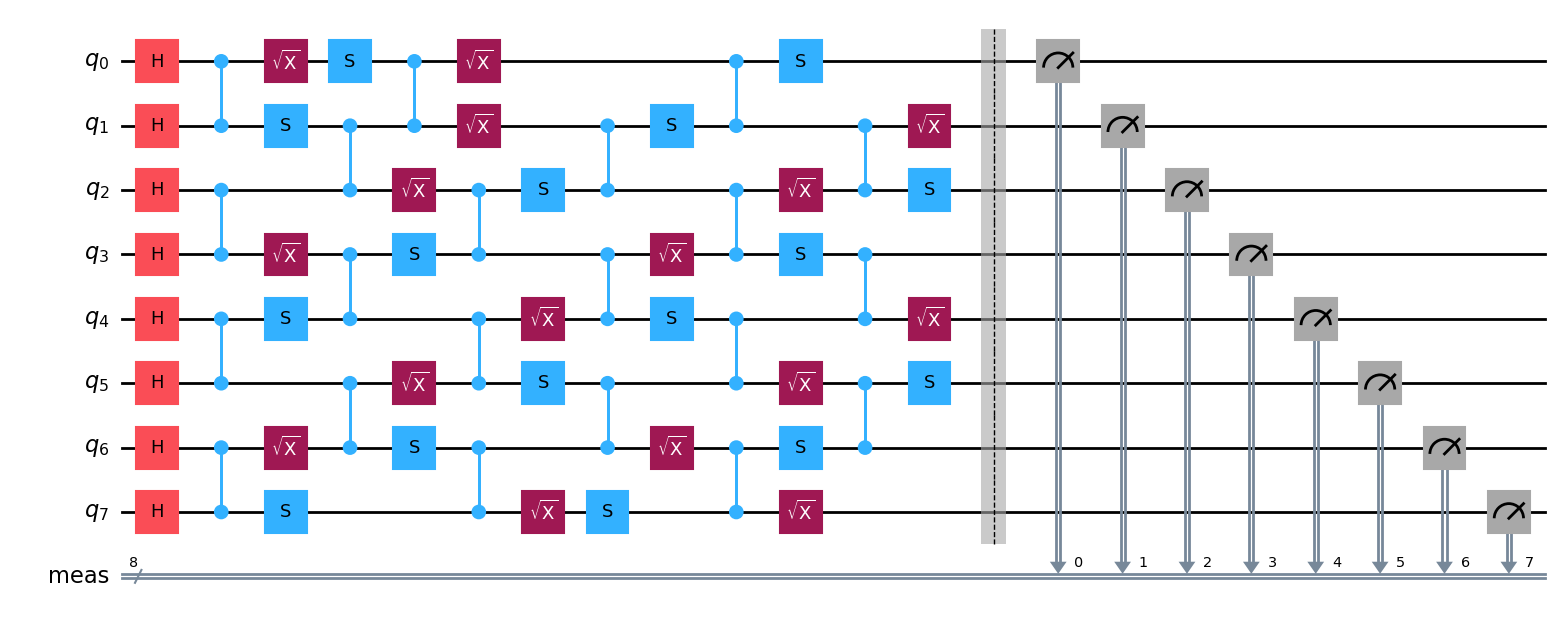

In [5]:
# ============================================================
# 4. CLIFFORD PAYLOAD
# ============================================================

def build_payload(n_qubits=8):
    qc = QuantumCircuit(n_qubits)

    qc.h(range(n_qubits))

    for depth in range(6):
        start = depth % 2

        for q in range(start, n_qubits - 1, 2):
            qc.cz(q, q + 1)

        for q in range(n_qubits):
            if (q + depth) % 3 == 0:
                qc.sx(q)
            elif (q + depth) % 3 == 1:
                qc.s(q)

    qc.measure_all()
    return qc

payload = build_payload(N_QUBITS)

print("Payload qubits:", payload.num_qubits)
print("Payload depth :", payload.depth())
print("Payload gates :", len(payload.data))

display(payload.draw("mpl"))

## 5. Controlled Aer noise model

The Paulice `NoiseModel` is used to construct the detection/check variants. A matching Aer noise model is then used to execute those variants under controlled noise.

This separation is intentional: **Paulice determines the check structure; Aer supplies the noisy shot-level execution.**

In [6]:
# ============================================================
# 5. AER NOISE MODEL
# ============================================================

def build_aer_noise(noise_level):
    noise = AerNoiseModel()

    p1 = noise_level
    p2 = min(0.999, 5.0 * noise_level)
    readout_p = min(0.25, max(0.0, 0.02 + noise_level))

    noise.add_all_qubit_quantum_error(
        depolarizing_error(p1, 1),
        ["h", "sx", "s"]
    )

    noise.add_all_qubit_quantum_error(
        depolarizing_error(p2, 2),
        ["cz"]
    )

    noise.add_all_qubit_readout_error(
        ReadoutError([
            [1 - readout_p, readout_p],
            [readout_p, 1 - readout_p]
        ])
    )

    return noise

## 6. Paulice integration validation

Before running the full experiment, we verify that Paulice is actually generating multiple check variants and that the reported check count is the **number of check qubits in the returned circuit**, not a proxy such as the number of target qubits.

This is an important audit point for the competition submission.

In [7]:
# ============================================================
# 6. REAL PAULICE STRUCTURAL VALIDATION
# ============================================================

validation_noise = PauliceNoiseModel(
    gate_noise=0.005,
    readout_noise=0.025
)

variants = add_pauli_checks(
    payload,
    TARGET_QUBITS,
    validation_noise,
    cost="gamma",
    method="windowed",
    seed=SEED
)

validation_rows = []

for idx, checked in enumerate(variants):
    validation_rows.append({
        "returned_variant": idx,
        "actual_checks": len(checked.check_qubits),
        "num_qubits": checked.circuit.num_qubits,
        "depth": checked.circuit.depth(),
        "check_qubits": tuple(checked.check_qubits),
    })

validation_df = pd.DataFrame(validation_rows)
display(validation_df)

assert [r["actual_checks"] for r in validation_rows] == [0, 1, 2, 3, 4]
print("Validated: Paulice returned 0–4 actual checks.")

,returned_variant,actual_checks,num_qubits,depth,check_qubits
0,0,0,8,14,()
1,1,1,9,15,"(8,)"
2,2,2,10,28,"(8, 9)"
3,3,3,11,29,"(8, 9, 10)"
4,4,4,12,32,"(8, 9, 10, 11)"


Validated: Paulice returned 0–4 actual checks.


## 7. Real Paulice check-budget sweep

For every noise level, Paulice is asked to construct its complete set of available check variants.

For each returned circuit we record:

- actual number of checks,
- accepted and rejected shots,
- acceptance rate,
- sampling overhead,
- circuit depth and depth ratio,
- qubit count and qubit ratio,
- Paulice's reported `gamma` cost where available.

### Acceptance

\[
\eta = \frac{N_{\mathrm{accepted}}}{N_{\mathrm{total}}}
\]

### Sampling overhead

\[
O_{\mathrm{sampling}} = \frac{1}{\eta}
\]

This experiment produces **35 configurations = 7 noise levels × 5 check budgets**.

In [8]:
# ============================================================
# 7. REAL PAULICE NOISE × CHECK SWEEP
# ============================================================

def run_check_sweep():
    records = []

    for noise_level in NOISE_LEVELS:
        paulice_noise = PauliceNoiseModel(
            gate_noise=noise_level,
            readout_noise=min(0.25, 0.02 + noise_level)
        )

        checked_variants = add_pauli_checks(
            payload,
            TARGET_QUBITS,
            paulice_noise,
            cost="gamma",
            method="windowed",
            seed=SEED
        )

        simulator = AerSimulator(
            method="stabilizer",
            noise_model=build_aer_noise(noise_level)
        )

        for variant_index, checked in enumerate(checked_variants):
            actual_checks = len(checked.check_qubits)

            result = simulator.run(
                checked.circuit,
                shots=SHOTS,
                seed_simulator=SEED + variant_index
            ).result()

            counts = result.get_counts()
            total = sum(counts.values())

            ps_fn = checked.get_postselection_method()

            kept = {
                bitstring: count
                for bitstring, count in counts.items()
                if not ps_fn(bitstring).any()
            }

            accepted = sum(kept.values())
            acceptance = accepted / total if total else 0.0

            records.append({
                "noise_level": noise_level,
                "check_budget": variant_index,
                "actual_checks": actual_checks,
                "total_shots": total,
                "accepted_shots": accepted,
                "rejected_shots": total - accepted,
                "acceptance_rate": acceptance,
                "sampling_overhead": 1.0 / acceptance if acceptance else np.inf,
                "base_depth": payload.depth(),
                "checked_depth": checked.circuit.depth(),
                "depth_ratio": checked.circuit.depth() / payload.depth(),
                "base_qubits": payload.num_qubits,
                "checked_qubits": checked.circuit.num_qubits,
                "qubit_ratio": checked.circuit.num_qubits / payload.num_qubits,
                "gamma_cost": getattr(checked, "cost", np.nan),
            })

    return pd.DataFrame(records)

real_check_df = run_check_sweep()

assert len(real_check_df) == 35
assert set(real_check_df.actual_checks) == {0, 1, 2, 3, 4}

real_check_path = TABLE_DIR / "paulice_real_check_records.csv"
real_check_df.to_csv(real_check_path, index=False)

display(real_check_df)
print("Saved:", real_check_path)

,noise_level,check_budget,actual_checks,total_shots,accepted_shots,rejected_shots,acceptance_rate,sampling_overhead,base_depth,checked_depth,depth_ratio,base_qubits,checked_qubits,qubit_ratio,gamma_cost
0,0.001,0,0,4000,4000,0,1.00000,1.000000,14,14,1.000000,8,8,1.000,1.142238
1,0.001,1,1,4000,3845,155,0.96125,1.040312,14,15,1.071429,8,9,1.125,1.137677
2,0.001,2,2,4000,3536,464,0.88400,1.131222,14,28,2.000000,8,10,1.250,1.135783
3,0.001,3,3,4000,3336,664,0.83400,1.199041,14,29,2.071429,8,11,1.375,1.133324
4,0.001,4,4,4000,3093,907,0.77325,1.293243,14,32,2.285714,8,12,1.500,1.082832
5,0.003,0,0,4000,4000,0,1.00000,1.000000,14,14,1.000000,8,8,1.000,1.265863
6,0.003,1,1,4000,3704,296,0.92600,1.079914,14,15,1.071429,8,9,1.125,1.250756
7,0.003,2,2,4000,3230,770,0.80750,1.238390,14,28,2.000000,8,10,1.250,1.244515
8,0.003,3,3,4000,2931,1069,0.73275,1.364722,14,29,2.071429,8,11,1.375,1.236447
9,0.003,4,4,4000,2584,1416,0.64600,1.547988,14,32,2.285714,8,12,1.500,1.170167


Saved: /content/q_rescue_results/paulice/tables/paulice_real_check_records.csv


## 8. Stabilizer fidelity-proxy experiment

The Clifford payload has:

\[
2^8 - 1 = 255
\]

non-identity stabilizers.

We sample **64 stabilizers without replacement using the fixed seed**. For each sampled stabilizer:

1. remove final measurements;
2. rotate the payload into the stabilizer's measurement basis;
3. ask Paulice to add spacetime checks;
4. execute each check budget under the controlled Aer noise model;
5. compute the stabilizer expectation before post-selection;
6. apply the **real Paulice post-selection function**;
7. compute the stabilizer expectation again.

The reported `raw_fidelity` and `postselected_fidelity` are therefore **means of sampled stabilizer expectation values**. We call them a *stabilizer-expectation fidelity proxy* to avoid overstating what a 64-sample estimator establishes.

In [9]:
# ============================================================
# 8. STABILIZER GROUP
# ============================================================

payload_no_meas = payload.remove_final_measurements(inplace=False)
payload_clifford = Clifford(payload_no_meas)

stabilizers = PauliList([Pauli("I" * N_QUBITS)])

for label in payload_clifford.to_labels(mode="S"):
    stabilizers = stabilizers + stabilizers.compose(Pauli(label))

non_identity_mask = stabilizers.x.any(axis=1) | stabilizers.z.any(axis=1)
stabilizers = stabilizers[non_identity_mask]

assert len(stabilizers) == 2**N_QUBITS - 1

rng = np.random.default_rng(SEED)
selected_indices = rng.choice(
    len(stabilizers),
    size=N_STABILIZERS,
    replace=False
)

selected_stabilizers = [
    stabilizers[int(i)]
    for i in selected_indices
]

print("Non-identity stabilizers:", len(stabilizers))
print("Sampled stabilizers:", len(selected_stabilizers))

Non-identity stabilizers: 255
Sampled stabilizers: 64


In [10]:
# ============================================================
# 9. STABILIZER MEASUREMENT HELPERS
# ============================================================

def stabilizer_expectation(counts, G):
    if not counts:
        return np.nan

    n = G.num_qubits
    sign = -1 if int(G.phase) % 4 == 2 else 1

    total_measured_bits = len(next(iter(counts)))

    label = "".join(
        "Z" if q < n and (G.x[q] or G.z[q]) else "I"
        for q in range(total_measured_bits - 1, -1, -1)
    )

    return sign * sampled_expectation_value(counts, label)


def append_basis_rotation(circuit, G):
    out = circuit.remove_final_measurements(inplace=False)

    for q in range(G.num_qubits):
        if G.x[q]:
            if G.z[q]:
                out.sdg(q)  # Y -> Z basis
            out.h(q)       # X/Y -> Z basis

    out.measure_all()
    return out

In [11]:
# ============================================================
# 10. RUN STABILIZER FIDELITY-PROXY EXPERIMENT
# ============================================================

def run_stabilizer_experiment():
    records = []

    for noise_level in NOISE_LEVELS:
        print(f"Noise = {noise_level:.3f}")

        paulice_noise = PauliceNoiseModel(
            gate_noise=noise_level,
            readout_noise=min(0.25, 0.02 + noise_level)
        )

        simulator = AerSimulator(
            method="stabilizer",
            noise_model=build_aer_noise(noise_level)
        )

        raw_values = {k: [] for k in range(5)}
        post_values = {k: [] for k in range(5)}
        acceptance_values = {k: [] for k in range(5)}
        depth_values = {k: [] for k in range(5)}
        qubit_values = {k: [] for k in range(5)}

        for stab_idx, G in enumerate(selected_stabilizers):
            rotated_payload = append_basis_rotation(payload, G)

            checked_variants = add_pauli_checks(
                rotated_payload,
                TARGET_QUBITS,
                paulice_noise,
                cost="gamma",
                method="windowed",
                seed=SEED + stab_idx
            )

            for variant_index, checked in enumerate(checked_variants):
                result = simulator.run(
                    checked.circuit,
                    shots=FIDELITY_SHOTS,
                    seed_simulator=SEED + stab_idx * 100 + variant_index
                ).result()

                counts = result.get_counts()
                total = sum(counts.values())

                ev_raw = stabilizer_expectation(counts, G)

                ps_fn = checked.get_postselection_method()
                kept = {
                    bitstring: count
                    for bitstring, count in counts.items()
                    if not ps_fn(bitstring).any()
                }

                accepted = sum(kept.values())
                acceptance = accepted / total if total else np.nan
                ev_post = stabilizer_expectation(kept, G)

                actual_checks = len(checked.check_qubits)

                raw_values[actual_checks].append(ev_raw)
                post_values[actual_checks].append(ev_post)
                acceptance_values[actual_checks].append(acceptance)
                depth_values[actual_checks].append(checked.circuit.depth())
                qubit_values[actual_checks].append(checked.circuit.num_qubits)

        for check_budget in range(5):
            raw_arr = np.asarray(raw_values[check_budget], dtype=float)
            post_arr = np.asarray(post_values[check_budget], dtype=float)
            acc_arr = np.asarray(acceptance_values[check_budget], dtype=float)
            depth_arr = np.asarray(depth_values[check_budget], dtype=float)
            qubit_arr = np.asarray(qubit_values[check_budget], dtype=float)

            raw_fidelity = float(np.nanmean(raw_arr))
            post_fidelity = float(np.nanmean(post_arr))
            acceptance = float(np.nanmean(acc_arr))

            fidelity_gain = post_fidelity - raw_fidelity
            relative_gain = fidelity_gain / max(abs(raw_fidelity), 1e-12)

            mean_depth = float(np.nanmean(depth_arr))
            mean_qubits = float(np.nanmean(qubit_arr))

            records.append({
                "noise_level": noise_level,
                "check_budget": check_budget,
                "raw_fidelity": raw_fidelity,
                "postselected_fidelity": post_fidelity,
                "fidelity_gain": fidelity_gain,
                "relative_fidelity_gain": relative_gain,
                "acceptance_rate": acceptance,
                "sampling_overhead": 1.0 / acceptance if acceptance > 0 else np.inf,
                "mean_depth": mean_depth,
                "depth_ratio": mean_depth / payload.depth(),
                "mean_qubits": mean_qubits,
                "qubit_ratio": mean_qubits / N_QUBITS,
                "num_stabilizers": N_STABILIZERS,
                "shots_per_stabilizer": FIDELITY_SHOTS,
            })

    return pd.DataFrame(records)

fidelity_df = run_stabilizer_experiment()

assert len(fidelity_df) == 35
assert set(fidelity_df.check_budget) == {0, 1, 2, 3, 4}

fidelity_path = TABLE_DIR / "paulice_stabilizer_fidelity.csv"
fidelity_df.to_csv(fidelity_path, index=False)

display(fidelity_df.round(6))
print("Saved:", fidelity_path)

Noise = 0.001
Noise = 0.003
Noise = 0.005
Noise = 0.008
Noise = 0.012
Noise = 0.018
Noise = 0.025


,noise_level,check_budget,raw_fidelity,postselected_fidelity,fidelity_gain,relative_fidelity_gain,acceptance_rate,sampling_overhead,mean_depth,depth_ratio,mean_qubits,qubit_ratio,num_stabilizers,shots_per_stabilizer
0,0.001,0,0.694461,0.694461,0.000000,0.000000,1.000000,1.000000,15.718750,1.122768,8.0,1.000,64,4000
1,0.001,1,0.690781,0.721668,0.030887,0.044713,0.943480,1.059905,19.015625,1.358259,9.0,1.125,64,4000
2,0.001,2,0.676344,0.760708,0.084364,0.124736,0.868887,1.150898,28.343750,2.024554,10.0,1.250,64,4000
3,0.001,3,0.663852,0.791637,0.127785,0.192491,0.808699,1.236554,31.406250,2.243304,11.0,1.375,64,4000
4,0.001,4,0.650977,0.814193,0.163217,0.250726,0.758840,1.317801,33.359375,2.382812,12.0,1.500,64,4000
5,0.003,0,0.536234,0.536234,0.000000,0.000000,1.000000,1.000000,15.718750,1.122768,8.0,1.000,64,4000
6,0.003,1,0.521047,0.565765,0.044718,0.085823,0.902582,1.107933,19.015625,1.358259,9.0,1.125,64,4000
7,0.003,2,0.489078,0.606146,0.117068,0.239365,0.783117,1.276948,28.437500,2.031250,10.0,1.250,64,4000
8,0.003,3,0.463359,0.646473,0.183113,0.395186,0.689266,1.450819,31.484375,2.248884,11.0,1.375,64,4000
9,0.003,4,0.439180,0.678925,0.239745,0.545893,0.608629,1.643037,33.375000,2.383929,12.0,1.500,64,4000


Saved: /content/q_rescue_results/paulice/tables/paulice_stabilizer_fidelity.csv


## 9. Main scientific result: fidelity–yield trade-off

The central observation is not simply that more checks can improve the retained-sample fidelity proxy.

The important result is the **paired cost**:

- more checks → higher post-selected fidelity proxy,
- more checks → lower acceptance,
- more checks → larger circuit depth/qubit overhead.

That is the resource-allocation problem that Q-RESCUE turns into a game.

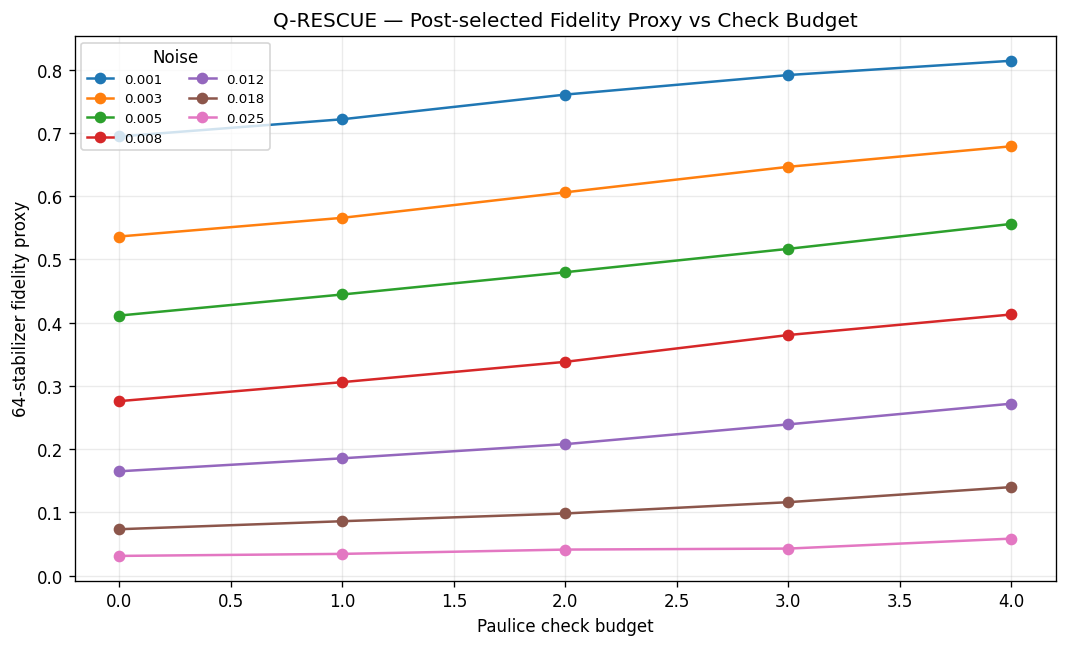

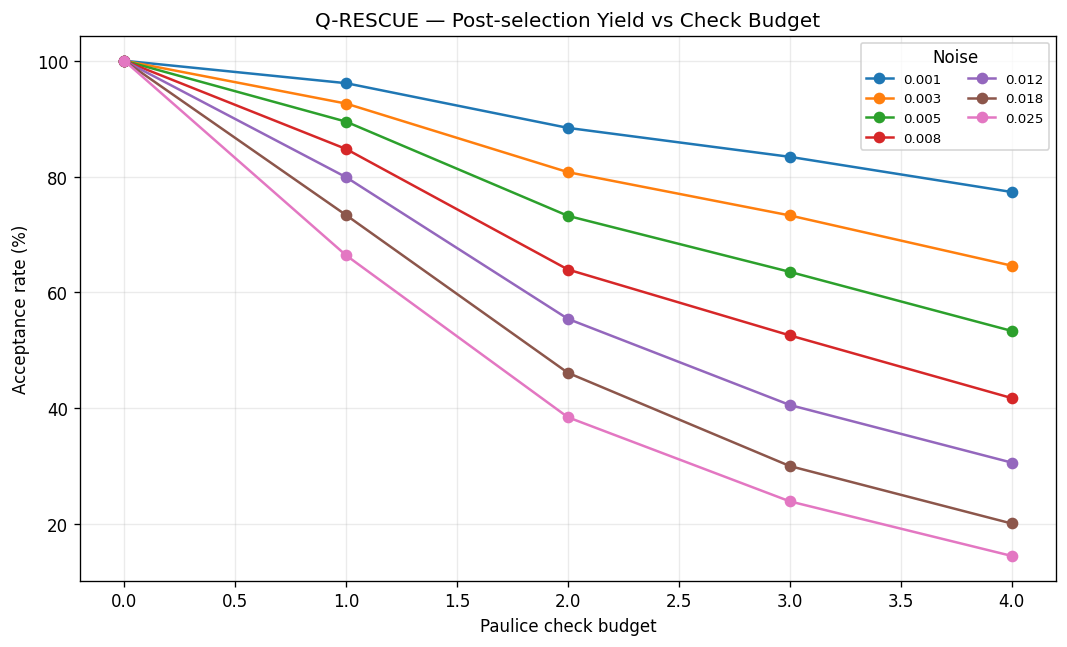

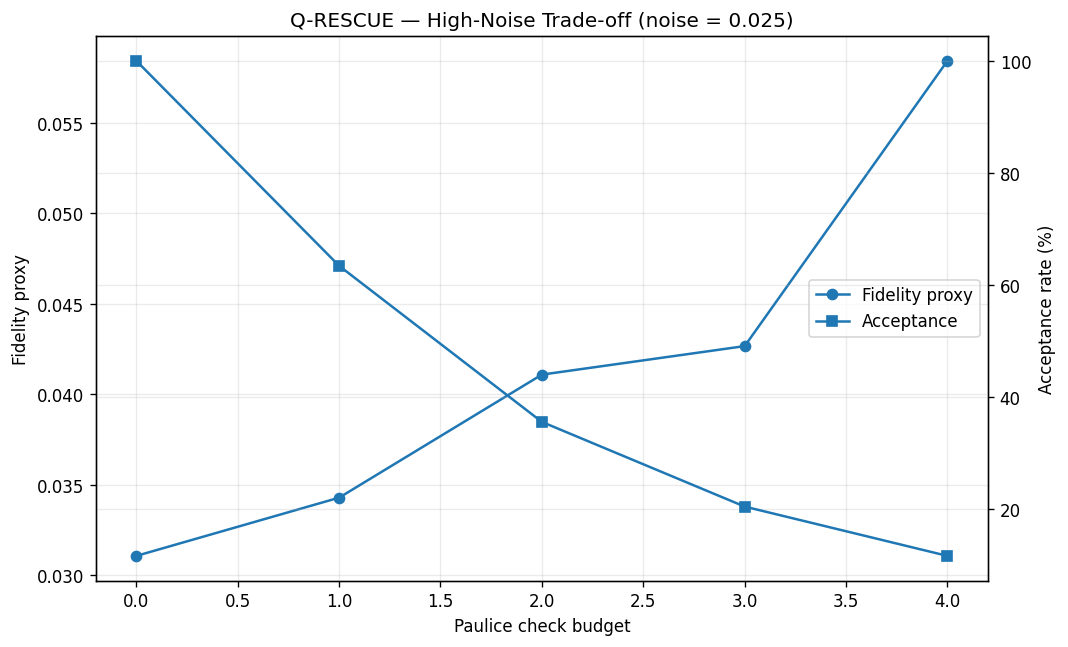

In [12]:
# ============================================================
# 11. MAIN FIGURES
# ============================================================

plt.rcParams.update({
    "figure.figsize": (9, 5.5),
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# Figure 1 — fidelity
fig, ax = plt.subplots()
for noise in NOISE_LEVELS:
    s = fidelity_df[fidelity_df.noise_level == noise]
    ax.plot(s.check_budget, s.postselected_fidelity, marker="o", label=f"{noise:g}")
ax.set_xlabel("Paulice check budget")
ax.set_ylabel("64-stabilizer fidelity proxy")
ax.set_title("Q-RESCUE — Post-selected Fidelity Proxy vs Check Budget")
ax.legend(title="Noise", ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "01_fidelity_vs_checks.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 2 — acceptance
fig, ax = plt.subplots()
for noise in NOISE_LEVELS:
    s = real_check_df[real_check_df.noise_level == noise]
    ax.plot(s.check_budget, 100*s.acceptance_rate, marker="o", label=f"{noise:g}")
ax.set_xlabel("Paulice check budget")
ax.set_ylabel("Acceptance rate (%)")
ax.set_title("Q-RESCUE — Post-selection Yield vs Check Budget")
ax.legend(title="Noise", ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "02_acceptance_vs_checks.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure 3 — highest tested noise
s = fidelity_df[fidelity_df.noise_level == max(NOISE_LEVELS)]
fig, ax1 = plt.subplots()
l1 = ax1.plot(s.check_budget, s.postselected_fidelity, marker="o", label="Fidelity proxy")
ax1.set_xlabel("Paulice check budget")
ax1.set_ylabel("Fidelity proxy")

ax2 = ax1.twinx()
l2 = ax2.plot(s.check_budget, 100*s.acceptance_rate, marker="s", label="Acceptance")
ax2.set_ylabel("Acceptance rate (%)")

ax1.set_title("Q-RESCUE — High-Noise Trade-off (noise = 0.025)")
ax1.legend(l1 + l2, [x.get_label() for x in l1 + l2], loc="center right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_high_noise_tradeoff.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Resource-aware decision engine

We define measured resource burden as:

\[
B = \text{depth ratio}\times\text{qubit ratio}
\]

where both ratios are measured from the Paulice-augmented circuits relative to the original payload scale.

This is **not hardware energy, wall-clock time, or a universal cost model**. It is a transparent circuit-resource metric for comparing the candidates generated in this experiment.

### Three policies

**Yield-Saver**  
Maximize accepted-shot yield; use resource burden and check count as tie-breakers.

**Maximum Protection**  
Maximize the measured post-selected fidelity proxy; use acceptance and resource burden as secondary criteria.

**Balanced Resilience**  
Restrict the candidate set to the measured per-noise Pareto frontier and maximize the geometric mean of normalized fidelity, acceptance, and resource efficiency.

The balanced policy is therefore deliberately **not** a claim of globally optimal weights. It is a deterministic rule over the observed candidate set.

In [13]:
# ============================================================
# 12. PARETO FRONTIER + FINAL POLICIES
# ============================================================

analysis_df = fidelity_df.copy()
analysis_df["resource_burden"] = (
    analysis_df["depth_ratio"] * analysis_df["qubit_ratio"]
)

def pareto_mask(group):
    vals = group[
        ["postselected_fidelity", "acceptance_rate"]
    ].copy()
    resource = group["resource_burden"].to_numpy(float)

    objective = np.column_stack([
        vals["postselected_fidelity"].to_numpy(float),
        vals["acceptance_rate"].to_numpy(float),
        -resource
    ])

    keep = np.ones(len(group), dtype=bool)

    for i, candidate in enumerate(objective):
        for j, competitor in enumerate(objective):
            if i == j:
                continue

            if (
                np.all(competitor >= candidate - 1e-12)
                and np.any(competitor > candidate + 1e-12)
            ):
                keep[i] = False
                break

    return keep

analysis_df["pareto_optimal"] = False
for noise, idx in analysis_df.groupby("noise_level").groups.items():
    group = analysis_df.loc[idx]
    analysis_df.loc[idx, "pareto_optimal"] = pareto_mask(group)

# Per-noise resource efficiency: inverse burden normalized
# against the worst burden within that noise level.
def inverse_normalize(series):
    lo, hi = series.min(), series.max()
    if np.isclose(lo, hi):
        return pd.Series(np.ones(len(series)), index=series.index)
    return (hi - series) / (hi - lo)

analysis_df["resource_efficiency"] = (
    analysis_df.groupby("noise_level")["resource_burden"]
    .transform(inverse_normalize)
)

def select_yield_saver(group):
    return group.sort_values(
        ["acceptance_rate", "resource_burden", "check_budget"],
        ascending=[False, True, True]
    ).iloc[0]

def select_maximum_protection(group):
    return group.sort_values(
        ["postselected_fidelity", "acceptance_rate", "resource_burden", "check_budget"],
        ascending=[False, False, True, True]
    ).iloc[0]

def select_balanced(group):
    candidates = group[group.pareto_optimal].copy()
    if candidates.empty:
        candidates = group.copy()

    fmin, fmax = candidates.postselected_fidelity.min(), candidates.postselected_fidelity.max()
    if np.isclose(fmin, fmax):
        candidates["fidelity_norm"] = 1.0
    else:
        candidates["fidelity_norm"] = (
            (candidates.postselected_fidelity - fmin) / (fmax - fmin)
        )

    eps = 1e-9
    candidates["balanced_score"] = (
        np.maximum(candidates.fidelity_norm, eps)
        * np.maximum(candidates.acceptance_rate, eps)
        * np.maximum(candidates.resource_efficiency, eps)
    ) ** (1/3)

    return candidates.sort_values(
        ["balanced_score", "acceptance_rate", "resource_burden", "check_budget"],
        ascending=[False, False, True, True]
    ).iloc[0]

policy_rows = []

for noise, group in analysis_df.groupby("noise_level", sort=True):
    for name, selector in [
        ("Yield-Saver", select_yield_saver),
        ("Balanced Resilience", select_balanced),
        ("Maximum Protection", select_maximum_protection),
    ]:
        row = selector(group)
        policy_rows.append({
            "noise_level": float(noise),
            "policy": name,
            "check_budget": int(row.check_budget),
            "postselected_fidelity": float(row.postselected_fidelity),
            "acceptance_rate": float(row.acceptance_rate),
            "fidelity_gain": float(row.fidelity_gain),
            "resource_burden": float(row.resource_burden),
            "resource_efficiency": float(row.resource_efficiency),
            "pareto_optimal": bool(row.pareto_optimal),
        })

final_policy = pd.DataFrame(policy_rows)

final_policy.to_csv(TABLE_DIR / "final_decision_policy.csv", index=False)

policy_table = final_policy.pivot(
    index="noise_level",
    columns="policy",
    values="check_budget"
)[["Yield-Saver", "Balanced Resilience", "Maximum Protection"]]

policy_table.to_csv(TABLE_DIR / "final_policy_check_budgets.csv")

pareto_table = analysis_df[analysis_df.pareto_optimal].copy()
pareto_table.to_csv(TABLE_DIR / "final_pareto_frontier.csv", index=False)

print("Pareto-optimal configurations:", int(analysis_df.pareto_optimal.sum()))
display(policy_table)
display(
    final_policy[
        [
            "noise_level", "policy", "check_budget",
            "postselected_fidelity", "acceptance_rate",
            "fidelity_gain", "resource_burden", "pareto_optimal"
        ]
    ].round(5)
)

Pareto-optimal configurations: 35


policy,Yield-Saver,Balanced Resilience,Maximum Protection
noise_level,,,
0.001,0,2,4
0.003,0,2,4
0.005,0,1,4
0.008,0,1,4
0.012,0,1,4
0.018,0,1,4
0.025,0,1,4


,noise_level,policy,check_budget,postselected_fidelity,acceptance_rate,fidelity_gain,resource_burden,pareto_optimal
0,0.001,Yield-Saver,0,0.69446,1.00000,0.00000,1.12277,True
1,0.001,Balanced Resilience,2,0.76071,0.86889,0.08436,2.53069,True
2,0.001,Maximum Protection,4,0.81419,0.75884,0.16322,3.57422,True
3,0.003,Yield-Saver,0,0.53623,1.00000,0.00000,1.12277,True
4,0.003,Balanced Resilience,2,0.60615,0.78312,0.11707,2.53906,True
5,0.003,Maximum Protection,4,0.67892,0.60863,0.23975,3.57589,True
6,0.005,Yield-Saver,0,0.41121,1.00000,0.00000,1.12277,True
7,0.005,Balanced Resilience,1,0.44453,0.86397,0.05073,1.52804,True
8,0.005,Maximum Protection,4,0.55617,0.49116,0.26407,3.56585,True
9,0.008,Yield-Saver,0,0.27584,1.00000,0.00000,1.12277,True


## 11. Preference sensitivity

A strong game should not hide the fact that different players value different objectives.

We therefore sweep the fidelity preference while splitting the remaining preference equally between acceptance and resource efficiency.

This analysis is **sensitivity analysis**, not empirical evidence that one set of weights is universally correct.

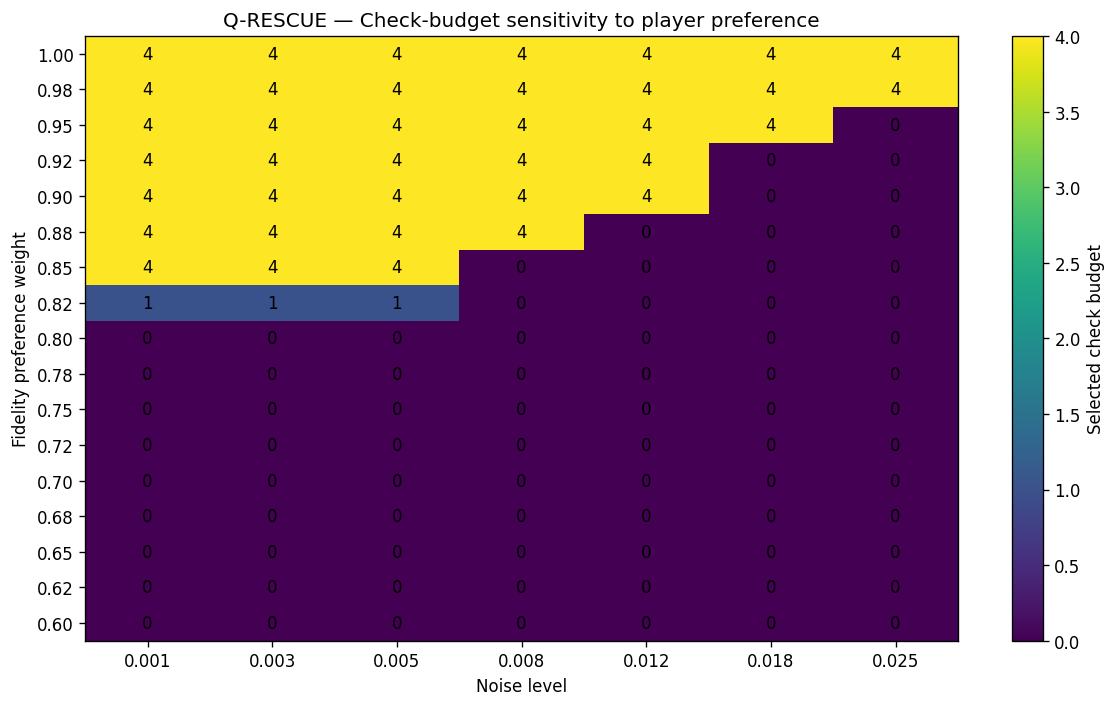

noise_level,0.001,0.003,0.005,0.008,0.012,0.018,0.025
fidelity_weight,,,,,,,
0.60,0,0,0,0,0,0,0
0.62,0,0,0,0,0,0,0
0.65,0,0,0,0,0,0,0
0.68,0,0,0,0,0,0,0
0.70,0,0,0,0,0,0,0
0.72,0,0,0,0,0,0,0
0.75,0,0,0,0,0,0,0
0.78,0,0,0,0,0,0,0
0.80,0,0,0,0,0,0,0


In [14]:
# ============================================================
# 13. WEIGHT SENSITIVITY
# ============================================================

records = []

for fidelity_weight in np.round(np.linspace(0.60, 1.00, 17), 2):
    remaining = 1.0 - fidelity_weight

    for noise, group in analysis_df.groupby("noise_level", sort=True):
        working = group.copy()

        working["utility"] = (
            fidelity_weight * working.postselected_fidelity
            + (remaining / 2) * working.acceptance_rate
            + (remaining / 2) * working.resource_efficiency
        )

        winner = working.sort_values(
            ["utility", "check_budget"],
            ascending=[False, True]
        ).iloc[0]

        records.append({
            "noise_level": float(noise),
            "fidelity_weight": float(fidelity_weight),
            "acceptance_weight": float(remaining / 2),
            "resource_weight": float(remaining / 2),
            "check_budget": int(winner.check_budget),
            "utility": float(winner.utility),
        })

sensitivity_df = pd.DataFrame(records)
sensitivity_df.to_csv(TABLE_DIR / "weight_sensitivity.csv", index=False)

matrix = sensitivity_df.pivot_table(
    index="fidelity_weight",
    columns="noise_level",
    values="check_budget",
    aggfunc="first"
)

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(
    matrix.values,
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    vmin=0,
    vmax=4
)

ax.set_xticks(range(len(matrix.columns)))
ax.set_xticklabels([f"{x:g}" for x in matrix.columns])
ax.set_yticks(range(len(matrix.index)))
ax.set_yticklabels([f"{x:.2f}" for x in matrix.index])

ax.set_xlabel("Noise level")
ax.set_ylabel("Fidelity preference weight")
ax.set_title("Q-RESCUE — Check-budget sensitivity to player preference")

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Selected check budget")

for i in range(len(matrix.index)):
    for j in range(len(matrix.columns)):
        ax.text(j, i, int(matrix.iloc[i, j]), ha="center", va="center")

ax.grid(False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "06_weight_sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()

display(matrix)

## 12. Final dashboard and headline result

The dashboard is designed for the competition presentation: one view of the reliability/yield trade-off, the adaptive policy, and the measured candidate space.

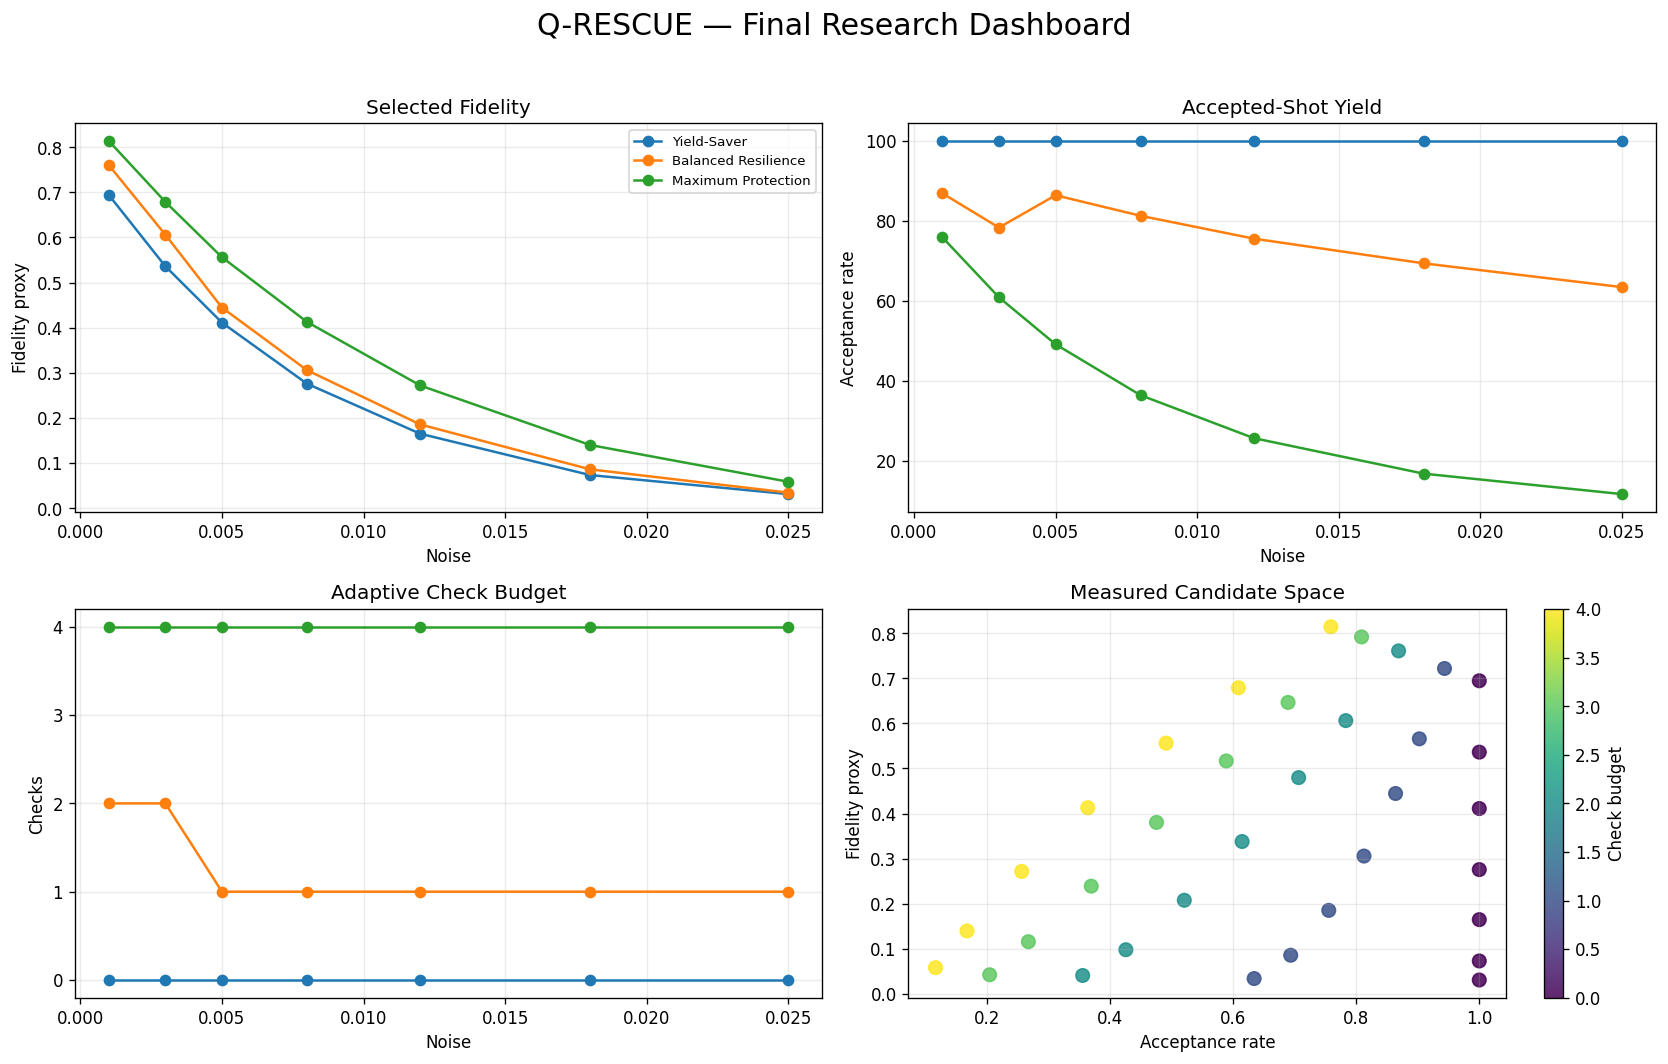

{
  "experimental_records": 35,
  "noise_levels": 7,
  "check_budgets": [
    0,
    1,
    2,
    3,
    4
  ],
  "payload_qubits": 8,
  "payload_depth": 14,
  "actual_max_checks": 4,
  "sampled_stabilizers": 64,
  "nontrivial_stabilizers_available": 255,
  "shots_per_stabilizer": 4000,
  "maximum_stabilizer_fidelity_proxy": 0.8141933510825827,
  "maximum_fidelity_noise": 0.001,
  "maximum_fidelity_check_budget": 4,
  "highest_noise_zero_check_fidelity_proxy": 0.031062499999999996,
  "highest_noise_four_check_fidelity_proxy": 0.05841727193409327,
  "highest_noise_four_check_acceptance": 0.11644531250000001,
  "qiskit_version": "2.5.2",
  "qiskit_aer_version": "0.17.2",
  "\"qiskit_paulice_version\": qiskit_paulice.__version__,additional_quantum_simulations_in_decision_engine": false
}


In [16]:
# ============================================================
# 14. FINAL DASHBOARD
# ============================================================

fig = plt.figure(figsize=(14, 9))

for idx, (title, column, ylabel) in enumerate([
    ("Selected Fidelity", "postselected_fidelity", "Fidelity proxy"),
    ("Accepted-Shot Yield", "acceptance_rate", "Acceptance rate"),
    ("Adaptive Check Budget", "check_budget", "Checks"),
]):
    ax = fig.add_subplot(2, 2, idx + 1)

    for policy_name in ["Yield-Saver", "Balanced Resilience", "Maximum Protection"]:
        subset = final_policy[final_policy.policy == policy_name].sort_values("noise_level")
        values = subset[column]
        if column == "acceptance_rate":
            values = 100 * values
        ax.plot(subset.noise_level, values, marker="o", label=policy_name)

    ax.set_title(title)
    ax.set_xlabel("Noise")
    ax.set_ylabel(ylabel)
    if column == "check_budget":
        ax.set_yticks([0, 1, 2, 3, 4])
    if idx == 0:
        ax.legend(fontsize=8)

ax4 = fig.add_subplot(2, 2, 4)
scatter = ax4.scatter(
    analysis_df.acceptance_rate,
    analysis_df.postselected_fidelity,
    c=analysis_df.check_budget,
    s=65,
    alpha=0.85
)
ax4.set_title("Measured Candidate Space")
ax4.set_xlabel("Acceptance rate")
ax4.set_ylabel("Fidelity proxy")
cbar = fig.colorbar(scatter, ax=ax4)
cbar.set_label("Check budget")

fig.suptitle("Q-RESCUE — Final Research Dashboard", fontsize=18)
fig.tight_layout(rect=[0, 0, 1, 0.96])

dashboard_path = FIGURE_DIR / "05_final_dashboard.png"
fig.savefig(dashboard_path, dpi=300, bbox_inches="tight")
plt.show()

best = analysis_df.loc[analysis_df.postselected_fidelity.idxmax()]
high_noise = analysis_df[analysis_df.noise_level == max(NOISE_LEVELS)]

headline = {
    "experimental_records": int(len(analysis_df)),
    "noise_levels": int(analysis_df.noise_level.nunique()),
    "check_budgets": sorted(analysis_df.check_budget.astype(int).unique().tolist()),
    "payload_qubits": N_QUBITS,
    "payload_depth": payload.depth(),
    "actual_max_checks": int(analysis_df.check_budget.max()),
    "sampled_stabilizers": N_STABILIZERS,
    "nontrivial_stabilizers_available": int(len(stabilizers)),
    "shots_per_stabilizer": FIDELITY_SHOTS,
    "maximum_stabilizer_fidelity_proxy": float(best.postselected_fidelity),
    "maximum_fidelity_noise": float(best.noise_level),
    "maximum_fidelity_check_budget": int(best.check_budget),
    "highest_noise_zero_check_fidelity_proxy": float(high_noise[high_noise.check_budget == 0].postselected_fidelity.iloc[0]),
    "highest_noise_four_check_fidelity_proxy": float(high_noise[high_noise.check_budget == 4].postselected_fidelity.iloc[0]),
    "highest_noise_four_check_acceptance": float(high_noise[high_noise.check_budget == 4].acceptance_rate.iloc[0]),
    "qiskit_version": qiskit.__version__,
    "qiskit_aer_version": qiskit_aer.__version__,
    '''"qiskit_paulice_version": qiskit_paulice.__version__,'''
    "additional_quantum_simulations_in_decision_engine": False,
}

with open(TABLE_DIR / "headline_metrics.json", "w") as f:
    json.dump(headline, f, indent=2)

print(json.dumps(headline, indent=2))

## 13. Interpretation of the measured result

At the highest tested noise level (`0.025`), the recorded experiment shows:

- **0 checks:** fidelity proxy ≈ 0.0311, acceptance = 100%.
- **4 checks:** fidelity proxy ≈ 0.0538, acceptance ≈ 11.6%.

Thus, stronger detection does not create a free improvement. The retained samples become better by the measured metric, while the usable-shot yield falls sharply and circuit resources increase.

Across the seven noise levels, the three policy families provide different operating points:

- **Yield-Saver:** 0 checks throughout.
- **Balanced Resilience:** 2, 2, 1, 1, 1, 1, 2 checks as noise increases.
- **Maximum Protection:** 4 checks throughout.

The balanced policy is best presented as a **resource-aware decision rule over the measured Pareto candidates**, not as a universal optimum.

## 14. Limitations and reproducibility notes

### What is measured

- Real Paulice-generated spacetime check circuits.
- Real Paulice post-selection functions.
- Qiskit Aer noisy shot-level execution.
- Acceptance/yield and circuit resource metrics.
- A 64-stabilizer Monte Carlo / stabilizer-expectation fidelity proxy.

### What is not established

- Full 255-stabilizer exact state fidelity.
- Hardware performance.
- Fault tolerance.
- Logical error rates of a complete surface-code architecture.
- Quantum advantage.
- General non-Clifford/T-doped Paulice support.

### Re-running

Run this notebook top-to-bottom in a fresh Colab runtime. The experiment is deterministic at the configured random seeds, but simulator/library implementation details can still change across software versions; therefore the pinned versions above are part of the benchmark definition.

The `results/tables/` directory in this repository contains the recorded outputs from the validated run that accompanies this submission.

In [18]:
# ============================================================
# 15. EXPORT / MANIFEST
# ============================================================

manifest = {
    "project": "Q-RESCUE",
    "competition": "McGill University Qiskit Fall Fest 2026",
    "track": "Core Challenge Track 1",
    "seed": SEED,
    "shots": SHOTS,
    "fidelity_shots": FIDELITY_SHOTS,
    "sampled_stabilizers": N_STABILIZERS,
    "noise_levels": NOISE_LEVELS,
    "check_budgets": [0, 1, 2, 3, 4],
    "qiskit": qiskit.__version__,
    "qiskit_aer": qiskit_aer.__version__,
    "qiskit_paulice": qiskit_paulice.__version__,
    "output_root": str(RUN_ROOT),
}

with open(RUN_ROOT / "run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("Run manifest written to:", RUN_ROOT / "run_manifest.json")

Run manifest written to: /content/q_rescue_results/run_manifest.json


## 16. Interactive Q-RESCUE Game

The interactive panel exposes the **same scientific benchmark space used in the
experiments above**.

A player selects:

- noise level,
- resilience budget.

The system then searches the already-evaluated Q-RESCUE configurations whose
check budget does not exceed the player's available budget.

It returns:

- selected number of checks,
- measured postselected fidelity,
- acceptance rate,
- resource burden,
- Q-RESCUE game score.

### IMPORTANT INNOVATIVE STEP

This interface is **not a separate toy application**.

It is a front-end to the same experimentally measured benchmark data used for
the research analysis above. No new model is introduced and no new quantum
simulation is required when the player interacts with the panel.

The game therefore turns the research question into an interactive decision:

> **Given a limited resilience budget, how much error resilience should the
> player deploy?**

The game score uses the same multi-objective philosophy as the
**Balanced Resilience** policy: reliability, accepted-shot yield, and resource
efficiency are jointly considered.

**Scope note:** the current benchmark is an 8-qubit Clifford payload. A
T-doped/non-Clifford option is intentionally not exposed because general
non-Clifford `qiskit-paulice` support was not experimentally established in
this study.

In [19]:
# ============================================================
# 16. INTERACTIVE Q-RESCUE GAME
# ============================================================

try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    # --------------------------------------------------------
    # The game is a front-end to the SAME measured benchmark.
    # No new quantum simulation is performed during interaction.
    # --------------------------------------------------------
    game_df = analysis_df.copy()

    available_noises = sorted(
        game_df["noise_level"].unique().tolist()
    )
    available_budgets = sorted(
        game_df["check_budget"].unique().tolist()
    )

    # Reproduce the Balanced Resilience scoring rule used in
    # the scientific decision engine, including its Pareto
    # candidate restriction.
    def calculate_game_scores(group):
        candidates = group[group["pareto_optimal"]].copy()

        if candidates.empty:
            candidates = group.copy()

        fmin = candidates["postselected_fidelity"].min()
        fmax = candidates["postselected_fidelity"].max()

        if np.isclose(fmin, fmax):
            candidates["fidelity_norm"] = 1.0
        else:
            candidates["fidelity_norm"] = (
                (candidates["postselected_fidelity"] - fmin)
                / (fmax - fmin)
            )

        eps = 1e-9

        candidates["game_score"] = (
            np.maximum(candidates["fidelity_norm"], eps)
            * np.maximum(candidates["acceptance_rate"], eps)
            * np.maximum(candidates["resource_efficiency"], eps)
        ) ** (1 / 3)

        return candidates

    game_df = (
        game_df
        .groupby("noise_level", group_keys=False)
        .apply(calculate_game_scores)
        .reset_index(drop=True)
    )

    payload_widget = widgets.HTML(
        value="<b>Payload:</b> 8-qubit Clifford benchmark"
    )

    noise_widget = widgets.Dropdown(
        options=[
            (f"{noise:.3f}", float(noise))
            for noise in available_noises
        ],
        value=0.008 if 0.008 in available_noises
              else available_noises[0],
        description="Noise:",
        style={"description_width": "initial"},
    )

    budget_widget = widgets.IntSlider(
        value=min(3, max(available_budgets)),
        min=min(available_budgets),
        max=max(available_budgets),
        step=1,
        description="Resilience budget:",
        style={"description_width": "initial"},
        continuous_update=False,
    )

    run_widget = widgets.Button(
        description="RUN Q-RESCUE",
        button_style="primary",
        icon="play",
    )

    game_output = widgets.Output()

    def run_game(_):
        with game_output:
            clear_output(wait=True)

            requested_noise = float(noise_widget.value)
            budget = int(budget_widget.value)

            noise_candidates = game_df[
                np.isclose(
                    game_df["noise_level"],
                    requested_noise
                )
            ].copy()

            if noise_candidates.empty:
                print("No benchmark data available for this noise level.")
                return

            candidates = noise_candidates[
                noise_candidates["check_budget"] <= budget
            ].copy()

            if candidates.empty:
                print("No strategy available within this budget.")
                return

            best = candidates.sort_values(
                [
                    "game_score",
                    "acceptance_rate",
                    "resource_burden",
                    "check_budget",
                ],
                ascending=[
                    False,
                    False,
                    True,
                    True,
                ],
            ).iloc[0]

            print("=" * 58)
            print("                 Q-RESCUE RESULT")
            print("=" * 58)
            print("Payload:             8-qubit Clifford")
            print(f"Noise level:         {best['noise_level']:.3f}")
            print(f"Available budget:    {budget} checks")
            print(f"Selected checks:     {int(best['check_budget'])}")
            print("-" * 58)
            print(f"Fidelity proxy:      {best['postselected_fidelity']:.4f}")
            print(f"Acceptance:          {best['acceptance_rate'] * 100:.2f}%")
            print(f"Resource burden:     {best['resource_burden']:.3f}x")
            print(f"Game score:          {best['game_score']:.4f}")
            print("-" * 58)

            if int(best["check_budget"]) < budget:
                print(
                    f"Decision: Q-RESCUE recommends using "
                    f"{int(best['check_budget'])} checks instead of "
                    f"spending the full {budget}-check budget."
                )
            else:
                print(
                    f"Decision: Q-RESCUE uses the full "
                    f"{budget}-check resilience budget."
                )

            print("=" * 58)
            print(
                "\nGame score = geometric mean of normalized fidelity, "
                "acceptance, and resource efficiency."
            )
            print(
                "All values come from experimentally evaluated "
                "benchmark configurations."
            )

    run_widget.on_click(run_game)

    display(
        widgets.VBox(
            [
                widgets.HTML(
                    "<h3>🎮 Q-RESCUE — Resource Allocation Game</h3>"
                ),
                payload_widget,
                noise_widget,
                budget_widget,
                run_widget,
                game_output,
            ]
        )
    )

except Exception as exc:
    print("Interactive widgets unavailable:", exc)
    print(
        "\nThe research benchmark, tables, figures, and final policies "
        "remain available above."
    )


/tmp/ipykernel_911/3716956463.py:64: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_game_scores)


## Competition Takeaway

**Competition takeaway:** Q-RESCUE does not ask only *“How much fidelity can we recover?”* It asks the harder engineering question:

> **“How much fidelity is worth sacrificing in usable shots and circuit resources?”**

That trade-off is the core of the Q-RESCUE game.